# Quantum noise floor: $\delta_k(\alpha, \zeta)$

This notebook characterizes the primitive-state leakage probability used in Eq. 23 / Eq. 24 by sweeping coherent amplitude $\alpha$ and squeezing $\zeta$.

The plotted quantity is

$$\delta_k = \langle \Theta_{\alpha,\zeta} | M_k | \Theta_{\alpha,\zeta}\rangle,$$

where $M_k$ is the phase-sector POVM element constructed by `ContinuousProtocol._create_phase_parity_measurement(k)`. By default we use $k=\lceil (d/m_c)/2\rceil$, matching the adjacent-section offset used for the floor $1-F_{\max}=2\delta_k$.

In [20]:
from pathlib import Path
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from qutip import Qobj, coherent, displace, expect, num, squeeze

repo_root = Path.cwd().resolve()
if repo_root.name == "notebook":
    repo_root = repo_root.parent
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from continuous import ContinuousProtocol
from measurements import IdealHeterodynePhaseMeasurement
from other_measurements import AdaptiveHomodynePhaseMeasurement

## Sweep parameters

Increase `N` if the largest `alpha` or most negative squeezing approaches the Fock cutoff. The quick cutoff check below reports the largest population in the final few Fock levels.

In [21]:
d = 16
m_i = 16
m_c = 8
N = 220

assert d % m_c == 0, "The phase-sector construction assumes d is divisible by m_c."

# Eq. 24 uses k = ceil(Delta_c / 2), where Delta_c = d / m_c.
delta_c = d / m_c
k = int(np.ceil(delta_c / 2))

alpha_values = np.linspace(3.0, 10.0, 15)
squeezing_values = np.linspace(-1.2, 0.0, 15)

print(f"Using k={k}, d={d}, m_c={m_c}, Delta_c={delta_c}, N={N}")

Using k=1, d=16, m_c=8, Delta_c=2.0, N=220


In [22]:
protocol = ContinuousProtocol(coherent(N, 0), res=d, m_i=m_i, m_c=m_c)
phase_sector = protocol._create_phase_parity_measurement(k)


def primitive_state(alpha, zeta, N=N):
    """Primitive state |Theta_{alpha,zeta}> used in the continuous simulations."""
    if np.isclose(zeta, 0.0):
        return coherent(N, alpha)
    return displace(N, alpha) * squeeze(N, zeta) * coherent(N, 0)


def delta_k(alpha, zeta):
    state = primitive_state(alpha, zeta)
    value = state.dag() * phase_sector * state
    return float(np.real_if_close(value.full()[0, 0]))


def cutoff_tail(alpha, zeta, tail_size=10):
    state = primitive_state(alpha, zeta)
    probabilities = np.abs(state.full().ravel()) ** 2
    return float(probabilities[-tail_size:].sum())

## Compute the grid

In [23]:
delta_grid = np.empty((len(squeezing_values), len(alpha_values)))

for row, zeta in enumerate(squeezing_values):
    for col, alpha in enumerate(alpha_values):
        delta_grid[row, col] = delta_k(alpha, zeta)

floor_grid = 2 * delta_grid

tail_checks = {
    "min_alpha_min_squeezing": cutoff_tail(alpha_values.min(), squeezing_values.min()),
    "max_alpha_min_squeezing": cutoff_tail(alpha_values.max(), squeezing_values.min()),
    "max_alpha_zero_squeezing": cutoff_tail(alpha_values.max(), 0.0),
}
tail_checks

{'min_alpha_min_squeezing': 1.95283947523554e-12,
 'max_alpha_min_squeezing': 0.0024379042593250157,
 'max_alpha_zero_squeezing': 6.643755275431682e-22}

## Heatmaps

The logarithmic color scale makes the noise floor visible over several orders of magnitude.

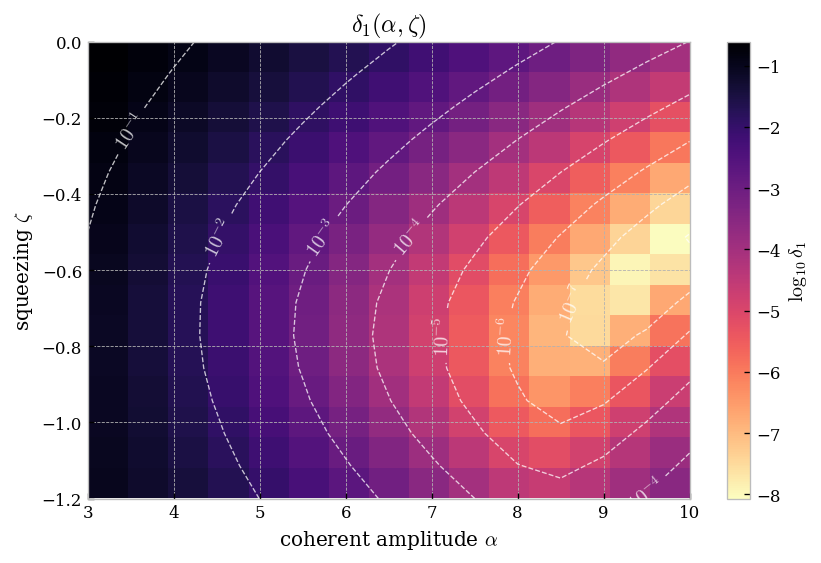

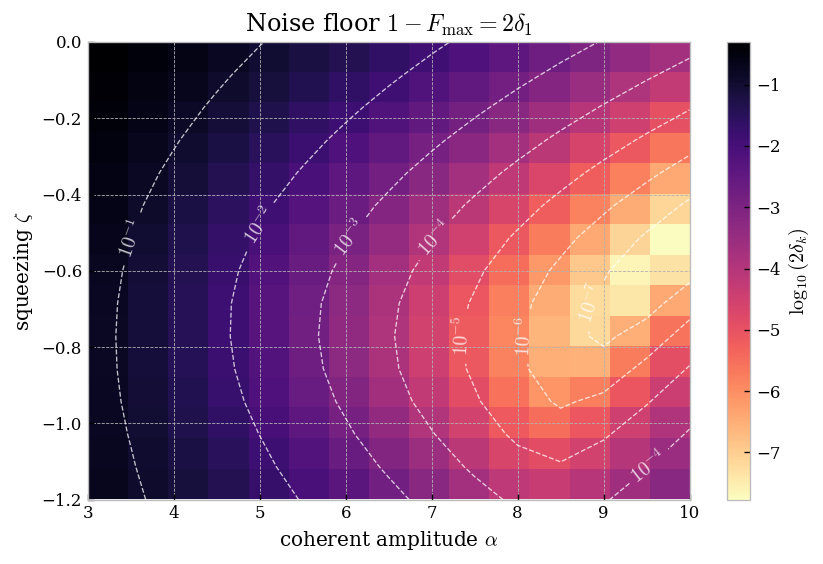

In [24]:
mpl.rcParams["text.usetex"] = False
mpl.rcParams["font.family"] = "DejaVu Serif"
plt.style.use("bmh")


def plot_log_heatmap(values, title, colorbar_label):
    safe_values = np.clip(values, np.finfo(float).tiny, None)
    log_values = np.log10(safe_values)

    fig, ax = plt.subplots(figsize=(7.2, 4.8), dpi=120)
    image = ax.imshow(
        log_values,
        origin="lower",
        aspect="auto",
        extent=[alpha_values.min(), alpha_values.max(), squeezing_values.min(), squeezing_values.max()],
        cmap="magma_r",
    )
    contours = ax.contour(
        alpha_values,
        squeezing_values,
        log_values,
        colors="white",
        linewidths=0.8,
        alpha=0.75,
    )
    ax.clabel(contours, inline=True, inline_spacing=7, fontsize=12, fmt=lambda x: f"$10^{{{x:.0f}}}$")
    colorbar = fig.colorbar(image, ax=ax)
    colorbar.set_label(colorbar_label)
    ax.set_xlabel(r"coherent amplitude $\alpha$")
    ax.set_ylabel(r"squeezing $\zeta$")
    ax.set_title(title)
    fig.tight_layout()
    return fig, ax


output_dir = repo_root / "results" / "delta_grid"
output_dir.mkdir(parents=True, exist_ok=True)

plot_log_heatmap(delta_grid, rf"$\delta_{{{k}}}(\alpha,\zeta)$", rf"$\log_{{10}} \delta_{{{k}}}$");
floor_fig, floor_ax = plot_log_heatmap(floor_grid, rf"Noise floor $1-F_{{\max}}=2\delta_{{{k}}}$", r"$\log_{10}(2\delta_k)$")
floor_fig.savefig(output_dir / f"floor_grid_d={d}_m_c={m_c}_N={N}.pdf", bbox_inches="tight")

## Slices through the grid

These one-dimensional cuts are useful for picking representative parameter values for the paper text.

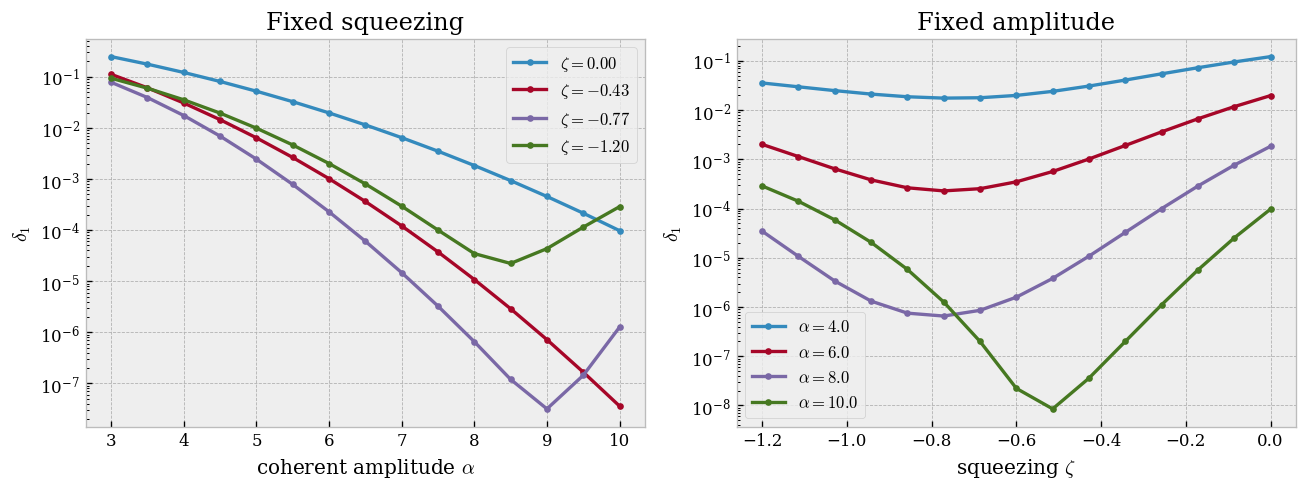

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=120)

for zeta in [0.0, -0.4, -0.8, -1.2]:
    row = np.argmin(np.abs(squeezing_values - zeta))
    axes[0].semilogy(alpha_values, delta_grid[row], ".-", label=rf"$\zeta={squeezing_values[row]:.2f}$")

for alpha in [4.0, 6.0, 8.0, 10.0]:
    col = np.argmin(np.abs(alpha_values - alpha))
    axes[1].semilogy(squeezing_values, delta_grid[:, col], ".-", label=rf"$\alpha={alpha_values[col]:.1f}$")

axes[0].set_xlabel(r"coherent amplitude $\alpha$")
axes[0].set_ylabel(rf"$\delta_{{{k}}}$")
axes[0].set_title("Fixed squeezing")
axes[0].legend()

axes[1].set_xlabel(r"squeezing $\zeta$")
axes[1].set_ylabel(rf"$\delta_{{{k}}}$")
axes[1].set_title("Fixed amplitude")
axes[1].legend()

fig.tight_layout()

## Optional: save data and figures

In [26]:
output_dir = repo_root / "results" / "delta_grid"
output_dir.mkdir(parents=True, exist_ok=True)
np.savez(
    output_dir / f"delta_grid_d={d}_m_c={m_c}_N={N}.npz",
    alpha_values=alpha_values,
    squeezing_values=squeezing_values,
    delta_grid=delta_grid,
    floor_grid=floor_grid,
    d=d,
    m_i=m_i,
    m_c=m_c,
    N=N,
    k=k,
)
plt.savefig(output_dir / f"delta_grid_d={d}_m_c={m_c}_N={N}.pdf", bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

## Heterodyne measurements

We repeat the one-dimensional slices using ideal heterodyne and Mark-II adaptive-homodyne phase measurements. In each case, the continuous phase POVM density is integrated over the same $d$ fine angular bins and then coarse-grained into the phase-sector classes used by the canonical measurement,

$$M_j^{(x)}=\sum_{\ell=0}^{m_c-1}M_{j+\ell\Delta_c}^{(\mathrm{fine},x)},\qquad \delta_j^{(x)}=\langle\Theta_{\alpha,\zeta}|M_j^{(x)}|\Theta_{\alpha,\zeta}\rangle,\qquad x\in\{\mathrm{het},\mathrm{ahd}\}.$$

Using identical angular boundaries and parameter slices isolates the leakage associated with each physical phase-measurement model. Dashed curves show heterodyne detection, dotted curves show the canonical phase measurement, and solid curves show adaptive homodyne detection. The adaptive model is the ideal Mark-II limit with instantaneous local-oscillator feedback. For the paper, we also produce a separate fixed-squeezing figure containing only the two intermediate squeezing values, which avoids obscuring the comparison with the $\zeta=0$ and $\zeta=-1.2$ curves.

In [27]:
delta_c_int = int(delta_c)
heterodyne_measurement = IdealHeterodynePhaseMeasurement(d, num(N))
heterodyne_angles = heterodyne_measurement.get_possible_results()
heterodyne_phase_sectors = [
    sum(
        heterodyne_measurement.POVM_elements[
            heterodyne_angles[result + index * delta_c_int]
        ]
        for index in range(m_c)
    )
    for result in range(delta_c_int)
]
heterodyne_phase_sector = heterodyne_phase_sectors[k]

adaptive_homodyne_cache_path = (
    repo_root / "results" / f"adaptive_homodyne_phase_matrix_N={N}.npz"
)
adaptive_homodyne_measurement = AdaptiveHomodynePhaseMeasurement(
    d,
    num(N),
    cache_path=adaptive_homodyne_cache_path,
)
adaptive_homodyne_angles = adaptive_homodyne_measurement.get_possible_results()
adaptive_homodyne_phase_sectors = [
    sum(
        adaptive_homodyne_measurement.POVM_elements[
            adaptive_homodyne_angles[result + index * delta_c_int]
        ]
        for index in range(m_c)
    )
    for result in range(delta_c_int)
]
adaptive_homodyne_phase_sector = adaptive_homodyne_phase_sectors[k]

heterodyne_completeness_error = np.linalg.norm(
    sum(heterodyne_phase_sectors).full() - np.eye(N)
)
assert heterodyne_completeness_error < 1e-8

adaptive_homodyne_completeness_error = np.linalg.norm(
    sum(adaptive_homodyne_phase_sectors).full() - np.eye(N)
)
assert adaptive_homodyne_completeness_error < 1e-8


phase_slice_state_cache = {}


def cached_phase_slice_state(alpha, zeta):
    key = (float(alpha), float(zeta))
    if key not in phase_slice_state_cache:
        phase_slice_state_cache[key] = primitive_state(*key)
    return phase_slice_state_cache[key]


def heterodyne_delta_k(alpha, zeta):
    state = cached_phase_slice_state(alpha, zeta)
    return float(np.real_if_close(expect(heterodyne_phase_sector, state)))


def adaptive_homodyne_delta_k(alpha, zeta):
    state = cached_phase_slice_state(alpha, zeta)
    return float(np.real_if_close(expect(adaptive_homodyne_phase_sector, state)))


{
    "heterodyne": heterodyne_completeness_error,
    "adaptive_homodyne": adaptive_homodyne_completeness_error,
}

/home/shoham/projects/BosonicEntanglementDistillation/src/measurements.py:138: ComplexWarning: Casting complex values to real discards the imaginary part
  offset = int(self.num.data[0, 0])


{'heterodyne': 1.9335948061685732e-11, 'adaptive_homodyne': 0.0}

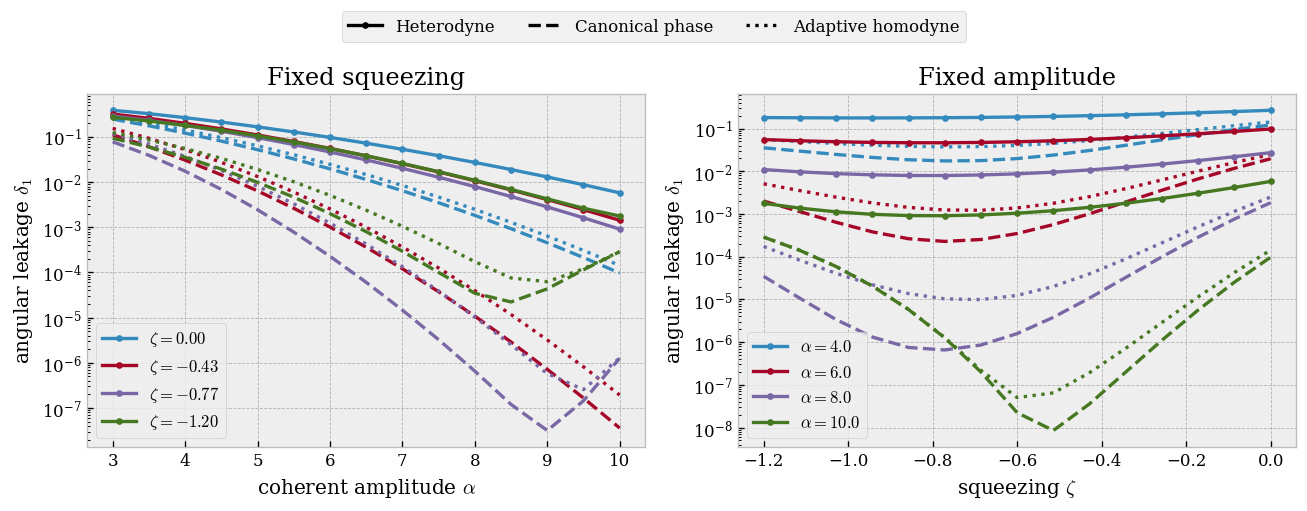

In [28]:
heterodyne_squeezing_targets = np.array([0.0, -0.4, -0.8, -1.2])
heterodyne_alpha_targets = np.array([4.0, 6.0, 8.0, 10.0])
heterodyne_squeezing_indices = [
    int(np.argmin(np.abs(squeezing_values - zeta)))
    for zeta in heterodyne_squeezing_targets
]
heterodyne_alpha_indices = [
    int(np.argmin(np.abs(alpha_values - alpha)))
    for alpha in heterodyne_alpha_targets
]

heterodyne_delta_cache = {}
adaptive_homodyne_delta_cache = {}


def cached_heterodyne_delta(alpha, zeta):
    key = (float(alpha), float(zeta))
    if key not in heterodyne_delta_cache:
        heterodyne_delta_cache[key] = heterodyne_delta_k(*key)
    return heterodyne_delta_cache[key]


def cached_adaptive_homodyne_delta(alpha, zeta):
    key = (float(alpha), float(zeta))
    if key not in adaptive_homodyne_delta_cache:
        adaptive_homodyne_delta_cache[key] = adaptive_homodyne_delta_k(*key)
    return adaptive_homodyne_delta_cache[key]


heterodyne_fixed_squeezing = np.array([
    [cached_heterodyne_delta(alpha, squeezing_values[row]) for alpha in alpha_values]
    for row in heterodyne_squeezing_indices
])
heterodyne_fixed_alpha = np.array([
    [cached_heterodyne_delta(alpha_values[col], zeta) for zeta in squeezing_values]
    for col in heterodyne_alpha_indices
])

adaptive_homodyne_fixed_squeezing = np.array([
    [cached_adaptive_homodyne_delta(alpha, squeezing_values[row]) for alpha in alpha_values]
    for row in heterodyne_squeezing_indices
])
adaptive_homodyne_fixed_alpha = np.array([
    [cached_adaptive_homodyne_delta(alpha_values[col], zeta) for zeta in squeezing_values]
    for col in heterodyne_alpha_indices
])

heterodyne_fig, heterodyne_axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=120)

for values, adaptive_values, row in zip(
    heterodyne_fixed_squeezing,
    adaptive_homodyne_fixed_squeezing,
    heterodyne_squeezing_indices,
):
    heterodyne_line, = heterodyne_axes[0].semilogy(
        alpha_values,
        values,
        ".--",
        label=rf"$\zeta={squeezing_values[row]:.2f}$",
    )
    heterodyne_axes[0].semilogy(
        alpha_values,
        delta_grid[row],
        ":",
        color=heterodyne_line.get_color(),
    )
    heterodyne_axes[0].semilogy(
        alpha_values,
        adaptive_values,
        "-",
        color=heterodyne_line.get_color(),
    )

for values, adaptive_values, col in zip(
    heterodyne_fixed_alpha,
    adaptive_homodyne_fixed_alpha,
    heterodyne_alpha_indices,
):
    heterodyne_line, = heterodyne_axes[1].semilogy(
        squeezing_values,
        values,
        ".--",
        label=rf"$\alpha={alpha_values[col]:.1f}$",
    )
    heterodyne_axes[1].semilogy(
        squeezing_values,
        delta_grid[:, col],
        ":",
        color=heterodyne_line.get_color(),
    )
    heterodyne_axes[1].semilogy(
        squeezing_values,
        adaptive_values,
        "-",
        color=heterodyne_line.get_color(),
    )

heterodyne_axes[0].set_xlabel(r"coherent amplitude $\alpha$")
heterodyne_axes[0].set_ylabel(rf"angular leakage $\delta_{{{k}}}$")
heterodyne_axes[0].set_title("Fixed squeezing")
heterodyne_axes[0].legend()

heterodyne_axes[1].set_xlabel(r"squeezing $\zeta$")
heterodyne_axes[1].set_ylabel(rf"angular leakage $\delta_{{{k}}}$")
heterodyne_axes[1].set_title("Fixed amplitude")
heterodyne_axes[1].legend()

measurement_legend = [
    Line2D([0], [0], color="black", linestyle="--", marker=".", label="Heterodyne"),
    Line2D([0], [0], color="black", linestyle=":", label="Canonical phase"),
    Line2D([0], [0], color="black", linestyle="-", label="Adaptive homodyne"),
]
heterodyne_fig.legend(
    handles=measurement_legend,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.02),
)
heterodyne_fig.tight_layout(rect=[0, 0, 1, 0.93])
heterodyne_fig.savefig(
    output_dir / f"heterodyne_slices_d={d}_m_c={m_c}_N={N}.pdf",
    bbox_inches="tight",
)

paper_fontsize = 14
paper_squeezing_positions = [1, 2]
paper_fig, paper_ax = plt.subplots(figsize=(7.0, 4.8), dpi=120)

for color_index, position in enumerate(paper_squeezing_positions):
    row = heterodyne_squeezing_indices[position]
    color = f"C{color_index}"
    paper_ax.semilogy(
        alpha_values,
        heterodyne_fixed_squeezing[position],
        linestyle="--",
        marker=".",
        linewidth=2,
        color=color,
        label=rf"$\zeta={squeezing_values[row]:.2f}$",
    )
    paper_ax.semilogy(
        alpha_values,
        delta_grid[row],
        linestyle=":",
        linewidth=2,
        color=color,
    )
    paper_ax.semilogy(
        alpha_values,
        adaptive_homodyne_fixed_squeezing[position],
        linestyle="-",
        linewidth=2,
        color=color,
    )

paper_ax.set_xlabel(r"coherent amplitude $\alpha$", fontsize=paper_fontsize)
paper_ax.set_ylabel(rf"angular leakage $\delta_{{{k}}}$", fontsize=paper_fontsize)
paper_ax.tick_params(axis="both", labelsize=paper_fontsize)
paper_ax.legend(loc="upper right", fontsize=paper_fontsize)
paper_fig.legend(
    handles=measurement_legend,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.02),
    fontsize=paper_fontsize,
)
paper_fig.tight_layout(rect=[0, 0, 1, 0.88])
paper_fig.savefig(
    output_dir / f"phase_measurement_fixed_squeezing_d={d}_m_c={m_c}_N={N}.pdf",
    bbox_inches="tight",
)
np.savez(
    output_dir / f"heterodyne_slices_d={d}_m_c={m_c}_N={N}.npz",
    alpha_values=alpha_values,
    squeezing_values=squeezing_values,
    squeezing_indices=heterodyne_squeezing_indices,
    alpha_indices=heterodyne_alpha_indices,
    fixed_squeezing=heterodyne_fixed_squeezing,
    fixed_alpha=heterodyne_fixed_alpha,
    adaptive_homodyne_fixed_squeezing=adaptive_homodyne_fixed_squeezing,
    adaptive_homodyne_fixed_alpha=adaptive_homodyne_fixed_alpha,
    canonical_fixed_squeezing=delta_grid[heterodyne_squeezing_indices],
    canonical_fixed_alpha=delta_grid[:, heterodyne_alpha_indices].T,
    d=d,
    m_i=m_i,
    m_c=m_c,
    N=N,
    k=k,
)

## Kerr nonlinear phase smearing

For $H_K=K a^{\dagger 2}a^2/2$ and $\gamma_K=Kt$, the Kerr unitary can be decomposed as

$$U_K=e^{i\gamma_K\bar n^2/2}e^{-i\gamma_K(2\bar n-1)n/2}e^{-i\gamma_K(n-\bar n)^2/2},$$

where $\bar n=\langle n\rangle$ is evaluated in the primitive state. The first factor is a global phase and the second is a deterministic phase rotation, which can be removed by updating the cavity phase reference. We therefore apply only the residual nonlinear unitary

$$U_{\mathrm{nl}}(\gamma_K)=e^{-i\gamma_K(n-\bar n)^2/2}$$

and use the angular leakage

$$\delta_k^{(K)}(\alpha,\zeta,\gamma_K)=\langle\Theta_{\alpha,\zeta}|U_{\mathrm{nl}}^\dagger M_k U_{\mathrm{nl}}|\Theta_{\alpha,\zeta}\rangle$$

as a proxy for the impact on the initial state. For the current parameters $\Delta_c=d/m_c=2$, $M_0+M_1=I$, so $\delta_1^{(K)}$ is the total probability assigned to the wrong angular-section class. This is not a simulation of the combined Kerr and photon-loss dynamics.

In [9]:
def photon_number_statistics(state):
    """Return <n> and Var(n) directly from a state's Fock probabilities."""
    probabilities = np.abs(state.full().ravel()) ** 2
    n_values = np.arange(state.shape[0], dtype=float)
    nbar = float(probabilities @ n_values)
    variance = float(probabilities @ (n_values - nbar) ** 2)
    return nbar, variance


def corrected_kerr_state(state, gamma_k):
    """Apply the nonlinear Kerr term after removing the correctable phase rotation."""
    amplitudes = state.full().ravel()
    n_values = np.arange(state.shape[0], dtype=float)
    nbar, _ = photon_number_statistics(state)
    phases = np.exp(-0.5j * gamma_k * (n_values - nbar) ** 2)
    return Qobj((phases * amplitudes)[:, None], dims=state.dims)


def kerr_delta_k(alpha, zeta, gamma_k):
    state = corrected_kerr_state(primitive_state(alpha, zeta), gamma_k)
    return float(np.real_if_close(expect(phase_sector, state)))


# Numerical checks of the zero-Kerr limit, sector normalization, and factorization.
validation_alpha = 7.0
validation_zeta = -0.8
validation_gamma = 1e-3
validation_state = primitive_state(validation_alpha, validation_zeta)
validation_evolved = corrected_kerr_state(validation_state, validation_gamma)
zero_kerr_error = abs(kerr_delta_k(validation_alpha, validation_zeta, 0.0) - delta_k(validation_alpha, validation_zeta))
sector_probability_sum = sum(
    expect(protocol._create_phase_parity_measurement(result), validation_evolved)
    for result in range(int(delta_c))
)

amplitudes = validation_state.full().ravel()
n_values = np.arange(N, dtype=float)
nbar, _ = photon_number_statistics(validation_state)
full_then_corrected = (
    np.exp(0.5j * validation_gamma * (2 * nbar - 1) * n_values)
    * np.exp(-0.5j * validation_gamma * n_values * (n_values - 1))
    * amplitudes
)
residual = validation_evolved.full().ravel()
factorization_fidelity = abs(np.vdot(full_then_corrected, residual)) ** 2

assert zero_kerr_error < 1e-12
assert np.isclose(sector_probability_sum, 1.0, atol=1e-12)
assert np.isclose(factorization_fidelity, 1.0, atol=1e-12)

{
    "zero_kerr_error": zero_kerr_error,
    "sector_probability_sum": float(np.real_if_close(sector_probability_sum)),
    "factorization_fidelity": factorization_fidelity,
}

{'zero_kerr_error': 0.0,
 'sector_probability_sum': 0.9999999999999961,
 'factorization_fidelity': 0.99999999999999}

### Leakage versus Kerr strength

The nonlinear phase accumulated over the populated photon-number range is controlled approximately by $|\gamma_K|\operatorname{Var}(n)$. Phase squeezing lowers the zero-Kerr angular leakage, but in the convention used here it also broadens the photon-number distribution and can make the state more sensitive to Kerr evolution.

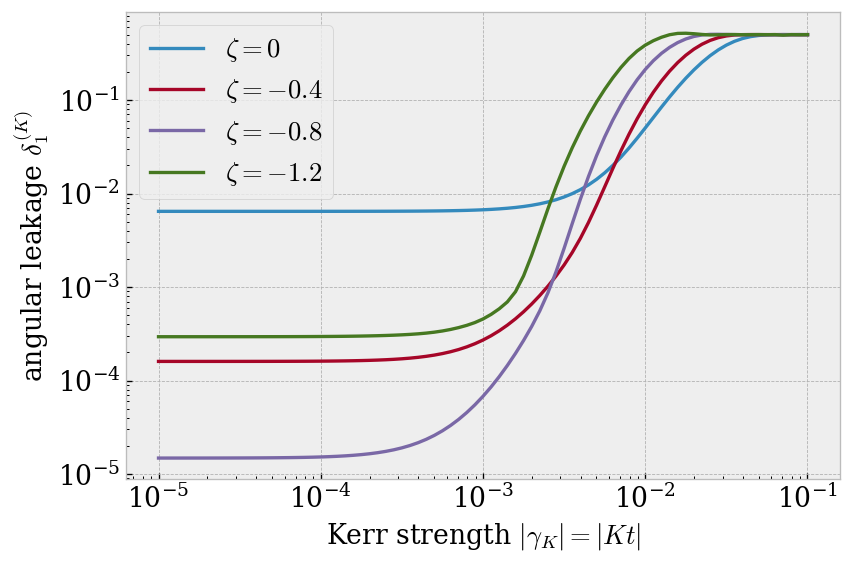

In [10]:
kerr_alpha = 7.0
kerr_squeezing_values = np.array([0.0, -0.4, -0.8, -1.2])
gamma_k_values = np.logspace(-5, -1, 81)
kerr_delta_values = np.empty((len(kerr_squeezing_values), len(gamma_k_values)))
number_variances = np.empty(len(kerr_squeezing_values))

kerr_fontsize = 16
fig, ax = plt.subplots(figsize=(7.2, 4.8), dpi=120)

for row, zeta in enumerate(kerr_squeezing_values):
    state = primitive_state(kerr_alpha, zeta)
    _, number_variances[row] = photon_number_statistics(state)
    kerr_delta_values[row] = [
        float(np.real_if_close(expect(phase_sector, corrected_kerr_state(state, gamma_k))))
        for gamma_k in gamma_k_values
    ]
    ax.loglog(
        gamma_k_values,
        kerr_delta_values[row],
        label=rf"$\zeta={zeta:g}$", # , $\operatorname{{Var}}(n)={number_variances[row]:.1f}$",
    )

ax.set_xlabel(r"Kerr strength $|\gamma_K|=|Kt|$", fontsize=kerr_fontsize)
ax.set_ylabel(rf"angular leakage $\delta_{{{k}}}^{{(K)}}$", fontsize=kerr_fontsize)
# ax.set_title(rf"Phase-corrected Kerr leakage at $\alpha={kerr_alpha:g}$")
ax.tick_params(axis="both", which="both", labelsize=kerr_fontsize)
ax.legend(fontsize=kerr_fontsize)
fig.tight_layout()

np.savez(
    output_dir / f"kerr_sweep_alpha={kerr_alpha:g}_d={d}_m_c={m_c}_N={N}.npz",
    gamma_k_values=gamma_k_values,
    squeezing_values=kerr_squeezing_values,
    delta_values=kerr_delta_values,
    number_variances=number_variances,
    alpha=kerr_alpha,
    d=d,
    m_c=m_c,
    N=N,
    k=k,
)
fig.savefig(
    output_dir / f"kerr_sweep_alpha={kerr_alpha:g}_d={d}_m_c={m_c}_N={N}.pdf",
    bbox_inches="tight",
)